In [1]:
#próbka po plazmie tlenowo-argonowej 0 i 2 s

from funkcje.Lorentz2Raman import *
colors = ["#808080","#FB7845", "#DB3688","#85154D","#260109"]

In [2]:
#import wszystkich mapek dla próbki 7
BASE = Path().resolve()
sciezka = BASE / "analiza" / "próbka7" / "dane_pomiarowe"

rs_PL_0s, I_PL_0s = importMap(sciezka/"WSe2_mapa_PL_7_0s.txt")
rs_PL_2s, I_PL_2s = importMap(sciezka/"WSe2_mapa_PL_7_2s.txt")
rs_PL_2s_proznia, I_PL_2s_proznia = importMap(sciezka/"WSe2_mapa_PL_7_2s_po_prozni.txt")



rs_Raman_0s, I_Raman_0s = importMap(sciezka/"WSe2_mapa_Raman_7_0s.txt")
rs_Raman_2s, I_Raman_2s = importMap(sciezka/"WSe2_mapa_Raman_7_2s.txt")
rs_Raman_2s_proznia, I_Raman_2s_proznia = importMap(sciezka/"WSe2_mapa_Raman_7_2s_po_prozni.txt")


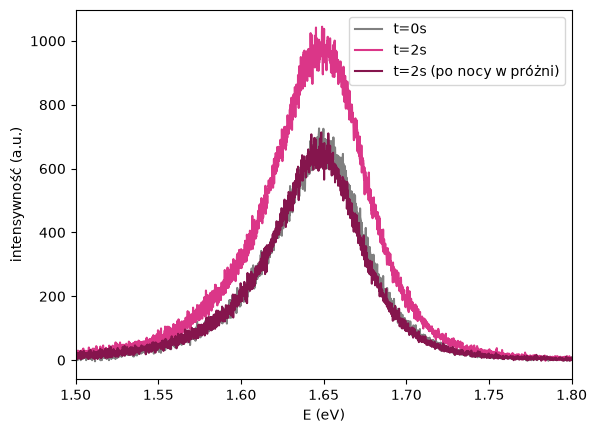

In [10]:
#testowe pojedyncze widma PL, żebym wiedziała co dopasować 

plt.plot(rs_PL_0s[8], I_PL_0s[9],label="t=0s",color='gray')
plt.plot(rs_PL_2s[10], I_PL_2s[10],label="t=2s",color=colors[2])
plt.plot(rs_PL_2s_proznia[10], I_PL_2s_proznia[8],label="t=2s (po nocy w próżni)",color=colors[3])
plt.xlabel(r"E (eV)")
plt.ylabel("intensywność (a.u.)")
plt.legend()
plt.xlim(1.5,1.8)

BASE = Path().resolve()
sciezka=BASE/"analiza"/"próbka6"/"wykresy"
plt.savefig(sciezka/'PL_2s.png')

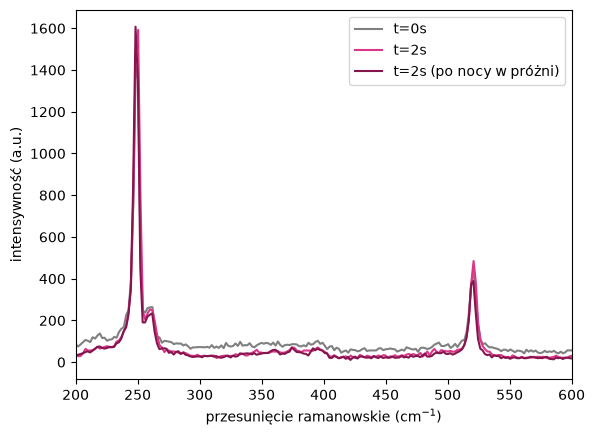

In [11]:
# testowe pojedyncze widma ramana, żebym wiedziała co dopasować 

plt.plot(rs_Raman_0s[10], I_Raman_0s[10],label="t=0s",color='gray')
plt.plot(rs_Raman_2s[10], I_Raman_2s[10],label="t=2s",color=colors[2])
plt.plot(rs_Raman_2s_proznia[10], I_Raman_2s_proznia[10],label="t=2s (po nocy w próżni)",color=colors[3])
plt.xlabel(r"przesunięcie ramanowskie (cm$^{-1}$)")
plt.ylabel("intensywność (a.u.)")
plt.legend()
plt.xlim(200,600)
plt.savefig(sciezka/'Raman_2s.png')

In [13]:
#dopasowanie PL

centers_PL_0s, fwhms_PL_0s, intensities_PL_0s = lorentz2map(rs_PL_0s, I_PL_0s, xmin=1.5, xmax=1.7)
centers_PL_2s, fwhms_PL_2s, intensities_PL_2s = lorentz2map(rs_PL_2s, I_PL_2s, xmin=1.55, xmax=1.75)
centers_PL_2s_proznia, fwhms_PL_2s_proznia, intensities_PL_2s_proznia = lorentz2map(rs_PL_2s_proznia, I_PL_2s_proznia, xmin=1.5, xmax=1.7)

In [14]:
#dopasowanie piku E i A

centers_Raman_EA_0s, fwhms_Raman_EA_0s, intensities_Raman_EA_0s = lorentz2map(rs_Raman_0s, I_Raman_0s, xmin=240, xmax=255)
centers_Raman_EA_2s, fwhms_Raman_EA_2s, intensities_Raman_EA_2s = lorentz2map(rs_Raman_2s, I_Raman_2s, xmin=240, xmax=255)
centers_Raman_EA_2s_proznia, fwhms_Raman_EA_2s_proznia, intensities_Raman_EA_2s_proznia = lorentz2map(rs_Raman_2s_proznia, I_Raman_2s_proznia, xmin=240, xmax=255)



In [ ]:
#dopasowanie piku 2LA(M)

centers_Raman_LA_0s, fwhms_Raman_LA_0s, intensities_Raman_LA_0s = lorentz2map(rs_Raman_0s, I_Raman_0s, xmin=255, xmax=265)
centers_Raman_LA_2s, fwhms_Raman_LA_2s, intensities_Raman_LA_2s = lorentz2map(rs_Raman_2s, I_Raman_2s, xmin=255, xmax=265)
centers_Raman_LA_2s_proznia, fwhms_Raman_LA_2s_proznia, intensities_Raman_LA_2s_proznia = lorentz2map(rs_Raman_2s_proznia, I_Raman_2s_proznia, xmin=255, xmax=265)

In [15]:
#usunięcie punktów mocno odstających - krawędzi monowarswty/samego podłoża = dla widm ramaniowskich niepewnosc fwhm w granicach warstosci
maska_Raman_EA_0s=(fwhms_Raman_EA_0s>=0) &(fwhms_Raman_EA_0s<=20)
fwhms_Raman_EA_0s=fwhms_Raman_EA_0s[maska_Raman_EA_0s]
centers_Raman_EA_0s=centers_Raman_EA_0s[maska_Raman_EA_0s]
intensities_Raman_EA_0s=intensities_Raman_EA_0s[maska_Raman_EA_0s]

maska_Raman_EA_2s=(fwhms_Raman_EA_2s>=0) &(fwhms_Raman_EA_2s<=20)
fwhms_Raman_EA_2s=fwhms_Raman_EA_2s[maska_Raman_EA_2s]
centers_Raman_EA_2s=centers_Raman_EA_2s[maska_Raman_EA_2s]
intensities_Raman_EA_2s=intensities_Raman_EA_2s[maska_Raman_EA_2s]


maska_Raman_EA_2s_proznia=(fwhms_Raman_EA_2s_proznia>=0) &(fwhms_Raman_EA_2s_proznia<=20)
fwhms_Raman_EA_2s_proznia=fwhms_Raman_EA_2s_proznia[maska_Raman_EA_2s_proznia]
centers_Raman_EA_2s_proznia=centers_Raman_EA_2s_proznia[maska_Raman_EA_2s_proznia]
intensities_Raman_EA_2s_proznia=intensities_Raman_EA_2s_proznia[maska_Raman_EA_2s_proznia]


In [16]:
mu_centers_PL_0s, sigma_centers_PL_0s = norm.fit(centers_PL_0s)
print(f"{mu_centers_PL_0s} ± {sigma_centers_PL_0s}")
x_centers_PL_0s,y_centers_PL_0s=gauss(mu_centers_PL_0s,sigma_centers_PL_0s)

mu_centers_PL_2s, sigma_centers_PL_2s = norm.fit(centers_PL_2s)
print(f"{mu_centers_PL_2s} ± {sigma_centers_PL_2s}")
x_centers_PL_2s,y_centers_PL_2s=gauss(mu_centers_PL_2s,sigma_centers_PL_2s)


mu_centers_PL_2s_proznia, sigma_centers_PL_2s_proznia = norm.fit(centers_PL_2s_proznia)
print(f"{mu_centers_PL_2s_proznia} ± {sigma_centers_PL_2s_proznia}")
x_centers_PL_2s_proznia,y_centers_PL_2s_proznia=gauss(mu_centers_PL_2s_proznia,sigma_centers_PL_2s_proznia)

1.6480565361516468 ± 0.0032392023232425612
1.6469709619449526 ± 0.0025553631654919706
1.6487787781285095 ± 0.003406172714960006


In [17]:
mu_intensities_PL_0s, sigma_intensities_PL_0s = norm.fit(intensities_PL_0s)
print(f"{mu_intensities_PL_0s} ± {sigma_intensities_PL_0s}")
x_intensities_PL_0s,y_intensities_PL_0s=gauss(mu_intensities_PL_0s,sigma_intensities_PL_0s)


mu_intensities_PL_2s, sigma_intensities_PL_2s = norm.fit(intensities_PL_2s)
print(f"{mu_intensities_PL_2s} ± {sigma_intensities_PL_2s}")
x_intensities_PL_2s,y_intensities_PL_2s=gauss(mu_intensities_PL_2s,sigma_intensities_PL_2s)


mu_intensities_PL_2s_proznia, sigma_intensities_PL_2s_proznia = norm.fit(intensities_PL_2s_proznia)
print(f"{mu_intensities_PL_2s_proznia} ± {sigma_intensities_PL_2s_proznia}")
x_intensities_PL_2s_proznia,y_intensities_PL_2s_proznia=gauss(mu_intensities_PL_2s_proznia,sigma_intensities_PL_2s_proznia)

670.1146342888644 ± 181.29034268876433
943.9172587548379 ± 205.38870753931195
653.8497603105253 ± 91.46946335263519


In [18]:
mu_fwhms_PL_0s, sigma_fwhms_PL_0s = norm.fit(fwhms_PL_0s)
print(f"{mu_fwhms_PL_0s} ± {sigma_fwhms_PL_0s}")
x_fwhms_PL_0s,y_fwhms_PL_0s=gauss(mu_fwhms_PL_0s,sigma_fwhms_PL_0s)


mu_fwhms_PL_2s, sigma_fwhms_PL_2s = norm.fit(fwhms_PL_2s)
print(f"{mu_fwhms_PL_2s} ± {sigma_fwhms_PL_2s}")
x_fwhms_PL_2s,y_fwhms_PL_2s=gauss(mu_fwhms_PL_2s,sigma_fwhms_PL_2s)


mu_fwhms_PL_2s_proznia, sigma_fwhms_PL_2s_proznia = norm.fit(fwhms_PL_2s_proznia)
print(f"{mu_fwhms_PL_2s_proznia} ± {sigma_fwhms_PL_2s_proznia}")
x_fwhms_PL_2s_proznia,y_fwhms_PL_2s_proznia=gauss(mu_fwhms_PL_2s_proznia,sigma_fwhms_PL_2s_proznia)

0.060606976998369144 ± 0.0037800460158817655
0.057672330535457804 ± 0.0025474623434683327
0.06000628843392234 ± 0.0024779556955638977


In [ ]:
mu_centers_Raman_EA_0s, sigma_centers_Raman_EA_0s = norm.fit(centers_Raman_EA_0s)
print(f"{mu_centers_Raman_EA_0s} ± {sigma_centers_Raman_EA_0s}")
x_centers_Raman_EA_0s,y_centers_Raman_EA_0s=gauss(mu_centers_Raman_EA_0s,sigma_centers_Raman_EA_0s)

mu_centers_Raman_EA_2s, sigma_centers_Raman_EA_2s = norm.fit(centers_Raman_EA_2s)
print(f"{mu_centers_Raman_EA_2s} ± {sigma_centers_Raman_EA_2s}")
x_centers_Raman_EA_2s,y_centers_Raman_EA_2s=gauss(mu_centers_Raman_EA_2s,sigma_centers_Raman_EA_2s)

249.30462638376878 ± 0.06204082083509172
249.44668306712364 ± 0.07532391542048239


In [ ]:
mu_intensities_Raman_EA_0s, sigma_intensities_Raman_EA_0s = norm.fit(intensities_Raman_EA_0s)
print(f"{mu_intensities_Raman_EA_0s} ± {sigma_intensities_Raman_EA_0s}")
x_intensities_Raman_EA_0s,y_intensities_Raman_EA_0s=gauss(mu_intensities_Raman_EA_0s,sigma_intensities_Raman_EA_0s)

mu_intensities_Raman_EA_2s, sigma_intensities_Raman_EA_2s = norm.fit(intensities_Raman_EA_2s)
print(f"{mu_intensities_Raman_EA_2s} ± {sigma_intensities_Raman_EA_2s}")
x_intensities_Raman_EA_2s,y_intensities_Raman_EA_2s=gauss(mu_intensities_Raman_EA_2s,sigma_intensities_Raman_EA_2s)

1873.2012755564074 ± 145.22435933339125
1750.0356107817472 ± 159.06931330791608


In [ ]:
mu_fwhms_Raman_EA_0s, sigma_fwhms_Raman_EA_0s = norm.fit(fwhms_Raman_EA_0s)
print(f"{mu_fwhms_Raman_EA_0s} ± {sigma_fwhms_Raman_EA_0s}")
x_fwhms_Raman_EA_0s,y_fwhms_Raman_EA_0s=gauss(mu_fwhms_Raman_EA_0s,sigma_fwhms_Raman_EA_0s)

mu_fwhms_Raman_EA_2s, sigma_fwhms_Raman_EA_2s = norm.fit(fwhms_Raman_EA_2s)
print(f"{mu_fwhms_Raman_EA_2s} ± {sigma_fwhms_Raman_EA_2s}")
x_fwhms_Raman_EA_2s,y_fwhms_Raman_EA_2s=gauss(mu_fwhms_Raman_EA_2s,sigma_fwhms_Raman_EA_2s)

4.4249134127056475 ± 0.2606172550559926
4.856079480778805 ± 0.2755527488735511


In [ ]:
mu_centers_Raman_LA_0s, sigma_centers_Raman_LA_0s = norm.fit(centers_Raman_LA_0s)
print(f"{mu_centers_Raman_LA_0s} ± {sigma_centers_Raman_LA_0s}")
x_centers_Raman_LA_0s,y_centers_Raman_LA_0s=gauss(mu_centers_Raman_LA_0s,sigma_centers_Raman_LA_0s)

mu_centers_Raman_LA_2s, sigma_centers_Raman_LA_2s = norm.fit(centers_Raman_LA_2s)
print(f"{mu_centers_Raman_LA_2s} ± {sigma_centers_Raman_LA_2s}")
x_centers_Raman_LA_2s,y_centers_Raman_LA_2s=gauss(mu_centers_Raman_LA_2s,sigma_centers_Raman_LA_2s)

259.7373390616713 ± 0.3600734252756898
259.8074956108281 ± 0.563669536951184


In [ ]:
mu_intensities_Raman_LA_0s, sigma_intensities_Raman_LA_0s = norm.fit(intensities_Raman_LA_0s)
print(f"{mu_intensities_Raman_LA_0s} ± {sigma_intensities_Raman_LA_0s}")
x_intensities_Raman_LA_0s,y_intensities_Raman_LA_0s=gauss(mu_intensities_Raman_LA_0s,sigma_intensities_Raman_LA_0s)

mu_intensities_Raman_LA_2s, sigma_intensities_Raman_LA_2s = norm.fit(intensities_Raman_LA_2s)
print(f"{mu_intensities_Raman_LA_2s} ± {sigma_intensities_Raman_LA_2s}")
x_intensities_Raman_LA_2s,y_intensities_Raman_LA_2s=gauss(mu_intensities_Raman_LA_2s,sigma_intensities_Raman_LA_2s)

252.43667156912764 ± 24.336548868446116
223.28677266613053 ± 44.66371437309177


In [ ]:
mu_fwhms_Raman_LA_0s, sigma_fwhms_Raman_LA_0s = norm.fit(fwhms_Raman_LA_0s)
print(f"{mu_fwhms_Raman_LA_0s} ± {sigma_fwhms_Raman_LA_0s}")
x_fwhms_Raman_LA_0s,y_fwhms_Raman_LA_0s=gauss(mu_fwhms_Raman_LA_0s,sigma_fwhms_Raman_LA_0s)

mu_fwhms_Raman_LA_2s, sigma_fwhms_Raman_LA_2s = norm.fit(fwhms_Raman_LA_2s)
print(f"{mu_fwhms_Raman_LA_2s} ± {sigma_fwhms_Raman_LA_2s}")
x_fwhms_Raman_LA_2s,y_fwhms_Raman_LA_2s=gauss(mu_fwhms_Raman_LA_2s,sigma_fwhms_Raman_LA_2s)

14.602425545384378 ± 1.233663092225457
19.60246066591709 ± 6.757594431157412
